In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import torch
from src.model import DiffCRModel
from src.diffusion import Diffusion
from src.sampler import DiffusionSampler
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import structural_similarity

PROJECT_ROOT = Path(r"E:\Rasengan\Cloud-Removal")
ROOT_DIR = Path(r"D:\CloudRemoval_Finetune")

sys.path.insert(0, str(PROJECT_ROOT))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Device: cuda
PyTorch: 2.14.0+cu130
CUDA available: True


In [6]:
CSV_PATH = ROOT_DIR / "patches" / "patch_manifest.csv"

ORIGINAL_CHECKPOINT = PROJECT_ROOT / "checkpoints" / "best_model.pth"

FINETUNED_CHECKPOINT = (
    ROOT_DIR / "finetune_checkpoints" / "latest_checkpoint.pth"
)

PATCH_SIZE = 256
BATCH_SIZE = 8
NUM_WORKERS = 0
SAMPLING_STEPS = 20

In [7]:
manifest_df = pd.read_csv(CSV_PATH)

print("Manifest shape:", manifest_df.shape)
print("\nColumns:")
print(manifest_df.columns.tolist())

print("\nSplit distribution:")
print(manifest_df["split"].value_counts())

print("\nSample test records:")
display(manifest_df[manifest_df["split"] == "test"].head())

Manifest shape: (173761, 5)

Columns:
['pair_id', 'patch_name', 'cloudy_path', 'clear_path', 'split']

Split distribution:
split
train    121479
valid     26314
test      25968
Name: count, dtype: int64

Sample test records:


,pair_id,patch_name,cloudy_path,clear_path,split
0,Pair20_Dharwad,patch_0_10112.tif,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,test
1,Pair20_Dharwad,patch_0_10240.tif,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,test
2,Pair20_Dharwad,patch_0_10368.tif,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,test
3,Pair20_Dharwad,patch_0_10496.tif,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,test
4,Pair20_Dharwad,patch_0_10624.tif,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,D:\CloudRemoval_Finetune\patches\Pair20_Dharwa...,test


In [8]:
class SatelliteTestDataset(Dataset):
    def __init__(self, manifest_df):
        self.samples = manifest_df[
            manifest_df["split"].str.lower() == "test"
        ][["cloudy_path", "clear_path"]].values.tolist()

    def read_image(self, path):
        with rasterio.open(path) as src:
            image = src.read().astype(np.float32)

        image = np.clip(image, 0, 1023) / 1023.0
        image = image * 2.0 - 1.0

        return torch.from_numpy(image)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        cloudy_path, clear_path = self.samples[index]

        cloudy = self.read_image(cloudy_path)
        clear = self.read_image(clear_path)

        if cloudy.shape != (3, PATCH_SIZE, PATCH_SIZE):
            raise ValueError(f"Unexpected cloudy shape: {cloudy.shape}")

        if clear.shape != (3, PATCH_SIZE, PATCH_SIZE):
            raise ValueError(f"Unexpected clear shape: {clear.shape}")

        return cloudy, clear


test_dataset = SatelliteTestDataset(manifest_df)

print("Test patches:", len(test_dataset))

Test patches: 25968


In [9]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Total test patches:", len(test_loader.dataset))

Test batches: 3246
Batch size: 8
Total test patches: 25968


In [10]:
original_model = DiffCRModel().to(DEVICE)
finetuned_model = DiffCRModel().to(DEVICE)

original_ckpt = torch.load(
    ORIGINAL_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

finetuned_ckpt = torch.load(
    FINETUNED_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

original_model.load_state_dict(original_ckpt["model"])
finetuned_model.load_state_dict(finetuned_ckpt["model"])

original_model.eval()
finetuned_model.eval()

print("Original checkpoint loaded.")
print("Fine-tuned checkpoint loaded.")
print("Fine-tuned epoch:", finetuned_ckpt["epoch"])
print("Fine-tuning lambda SAM:", finetuned_ckpt["lambda_sam"])

Original checkpoint loaded.
Fine-tuned checkpoint loaded.
Fine-tuned epoch: 10
Fine-tuning lambda SAM: 0.01


In [11]:
diffusion = Diffusion(device=DEVICE)
sampler = DiffusionSampler(diffusion)

print("Diffusion timesteps:", diffusion.timesteps)
print("Sampling steps:", SAMPLING_STEPS)

Diffusion timesteps: 1000
Sampling steps: 20


In [12]:
cloudy, clear = next(iter(test_loader))

cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

torch.manual_seed(42)
initial_noise = torch.randn_like(cloudy)

with torch.no_grad():
    pred_original = sampler.sample(
        original_model,
        cloudy,
        sampling_steps=SAMPLING_STEPS,
        initial_noise=initial_noise
    )

    pred_finetuned = sampler.sample(
        finetuned_model,
        cloudy,
        sampling_steps=SAMPLING_STEPS,
        initial_noise=initial_noise
    )

print("Cloudy shape:", cloudy.shape)
print("Ground truth shape:", clear.shape)
print("Original prediction shape:", pred_original.shape)
print("Fine-tuned prediction shape:", pred_finetuned.shape)

print("\nOriginal prediction range:",
      pred_original.min().item(), pred_original.max().item())

print("Fine-tuned prediction range:",
      pred_finetuned.min().item(), pred_finetuned.max().item())

print("\nNaN in original:", torch.isnan(pred_original).any().item())
print("NaN in fine-tuned:", torch.isnan(pred_finetuned).any().item())

Cloudy shape: torch.Size([8, 3, 256, 256])
Ground truth shape: torch.Size([8, 3, 256, 256])
Original prediction shape: torch.Size([8, 3, 256, 256])
Fine-tuned prediction shape: torch.Size([8, 3, 256, 256])

Original prediction range: -0.7817216515541077 -0.5090035796165466
Fine-tuned prediction range: -0.8877883553504944 -0.43561434745788574

NaN in original: False
NaN in fine-tuned: False


In [13]:
def calculate_metrics(prediction, target):
    prediction = ((prediction + 1) / 2).clamp(0, 1)
    target = ((target + 1) / 2).clamp(0, 1)

    pred_np = prediction.detach().cpu().numpy()
    target_np = target.detach().cpu().numpy()

    batch_metrics = []

    for i in range(pred_np.shape[0]):
        pred = np.transpose(pred_np[i], (1, 2, 0))
        gt = np.transpose(target_np[i], (1, 2, 0))

        mae = np.mean(np.abs(pred - gt))

        mse = np.mean((pred - gt) ** 2)
        psnr = 10 * np.log10(1.0 / mse) if mse > 0 else float("inf")

        ssim = structural_similarity(
            gt,
            pred,
            channel_axis=-1,
            data_range=1.0
        )

        dot_product = np.sum(pred * gt, axis=-1)
        pred_norm = np.linalg.norm(pred, axis=-1)
        gt_norm = np.linalg.norm(gt, axis=-1)

        denominator = pred_norm * gt_norm
        valid = denominator > 1e-8

        cosine = np.zeros_like(dot_product)
        cosine[valid] = dot_product[valid] / denominator[valid]
        cosine = np.clip(cosine[valid], -1.0, 1.0)

        sam = np.degrees(np.arccos(cosine)).mean()

        batch_metrics.append([mae, psnr, ssim, sam])

    return np.array(batch_metrics)


print("Evaluation metrics function defined.")

Evaluation metrics function defined.


In [14]:
original_metrics = calculate_metrics(pred_original, clear)
finetuned_metrics = calculate_metrics(pred_finetuned, clear)

metric_names = ["MAE", "PSNR", "SSIM", "SAM"]

comparison = pd.DataFrame({
    "Metric": metric_names,
    "Original Model": original_metrics.mean(axis=0),
    "Fine-tuned Model": finetuned_metrics.mean(axis=0)
})

display(comparison)

,Metric,Original Model,Fine-tuned Model
0,MAE,0.066457,0.024570
1,PSNR,23.040075,30.141022
2,SSIM,0.781460,0.879025
3,SAM,9.853660,7.610110


In [15]:
original_all_metrics = []
finetuned_all_metrics = []

In [16]:
import time

start_time = time.time()

for batch_idx, (cloudy_batch, clear_batch) in enumerate(test_loader):

    cloudy_batch = cloudy_batch.to(DEVICE)
    clear_batch = clear_batch.to(DEVICE)

    initial_noise = torch.randn_like(cloudy_batch)

    with torch.no_grad():
        pred_original_batch = sampler.sample(
            original_model,
            cloudy_batch,
            sampling_steps=SAMPLING_STEPS,
            initial_noise=initial_noise
        )

        pred_finetuned_batch = sampler.sample(
            finetuned_model,
            cloudy_batch,
            sampling_steps=SAMPLING_STEPS,
            initial_noise=initial_noise
        )

    original_batch_metrics = calculate_metrics(
        pred_original_batch,
        clear_batch
    )

    finetuned_batch_metrics = calculate_metrics(
        pred_finetuned_batch,
        clear_batch
    )

    original_all_metrics.extend(original_batch_metrics)
    finetuned_all_metrics.extend(finetuned_batch_metrics)

    if (batch_idx + 1) % 100 == 0:
        elapsed = (time.time() - start_time) / 60

        print(
            f"Batch {batch_idx + 1}/{len(test_loader)} | "
            f"Processed {(batch_idx + 1) * BATCH_SIZE} patches | "
            f"Elapsed: {elapsed:.2f} min"
        )

print("\nFull test inference completed.")
print("Original evaluated:", len(original_all_metrics))
print("Fine-tuned evaluated:", len(finetuned_all_metrics))
print("Total time:", round((time.time() - start_time) / 60, 2), "minutes")

Batch 100/3246 | Processed 800 patches | Elapsed: 10.32 min
Batch 200/3246 | Processed 1600 patches | Elapsed: 20.29 min
Batch 300/3246 | Processed 2400 patches | Elapsed: 29.88 min
Batch 400/3246 | Processed 3200 patches | Elapsed: 39.55 min
Batch 500/3246 | Processed 4000 patches | Elapsed: 49.15 min
Batch 600/3246 | Processed 4800 patches | Elapsed: 58.75 min
Batch 700/3246 | Processed 5600 patches | Elapsed: 68.34 min
Batch 800/3246 | Processed 6400 patches | Elapsed: 77.96 min
Batch 900/3246 | Processed 7200 patches | Elapsed: 87.55 min
Batch 1000/3246 | Processed 8000 patches | Elapsed: 97.15 min
Batch 1100/3246 | Processed 8800 patches | Elapsed: 155.57 min
Batch 1200/3246 | Processed 9600 patches | Elapsed: 165.14 min
Batch 1300/3246 | Processed 10400 patches | Elapsed: 174.76 min
Batch 1400/3246 | Processed 11200 patches | Elapsed: 184.45 min
Batch 1500/3246 | Processed 12000 patches | Elapsed: 194.16 min
Batch 1600/3246 | Processed 12800 patches | Elapsed: 203.91 min
Batch 17

In [17]:
original_all_metrics = np.array(original_all_metrics)
finetuned_all_metrics = np.array(finetuned_all_metrics)

metric_names = ["MAE", "PSNR", "SSIM", "SAM"]

results = pd.DataFrame({
    "Metric": metric_names,
    "Original Model": original_all_metrics.mean(axis=0),
    "Fine-tuned Model": finetuned_all_metrics.mean(axis=0)
})

results["Difference"] = (
    results["Fine-tuned Model"] - results["Original Model"]
)

display(results.round(6))

,Metric,Original Model,Fine-tuned Model,Difference
0,MAE,0.038501,0.043533,0.005032
1,PSNR,28.104948,27.046183,-1.058765
2,SSIM,0.825559,0.813294,-0.012265
3,SAM,8.973950,9.385512,0.411562


In [18]:
BEST_FINETUNED_CHECKPOINT = (
    ROOT_DIR / "finetune_checkpoints" / "best_finetuned_model.pth"
)

print("Best checkpoint exists:", BEST_FINETUNED_CHECKPOINT.exists())

if BEST_FINETUNED_CHECKPOINT.exists():
    best_ckpt = torch.load(
        BEST_FINETUNED_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint keys:", best_ckpt.keys())
    print("Best checkpoint epoch:", best_ckpt.get("epoch"))
    print("Best validation loss:", best_ckpt.get("best_val_loss"))
else:
    print("No separate best fine-tuned checkpoint found.")

Best checkpoint exists: False
No separate best fine-tuned checkpoint found.


In [19]:
test_manifest = manifest_df[
    manifest_df["split"].str.lower() == "test"
].reset_index(drop=True)

pair_results = pd.DataFrame({
    "pair_id": test_manifest["pair_id"],
    "Original_MAE": original_all_metrics[:, 0],
    "Finetuned_MAE": finetuned_all_metrics[:, 0],
    "Original_PSNR": original_all_metrics[:, 1],
    "Finetuned_PSNR": finetuned_all_metrics[:, 1],
    "Original_SSIM": original_all_metrics[:, 2],
    "Finetuned_SSIM": finetuned_all_metrics[:, 2],
    "Original_SAM": original_all_metrics[:, 3],
    "Finetuned_SAM": finetuned_all_metrics[:, 3]
})

scene_comparison = pair_results.groupby("pair_id").mean(numeric_only=True)

display(scene_comparison.round(5))

,Original_MAE,Finetuned_MAE,Original_PSNR,Finetuned_PSNR,Original_SSIM,Finetuned_SSIM,Original_SAM,Finetuned_SAM
pair_id,,,,,,,,
Pair20_Dharwad,0.02686,0.03738,30.3515,27.588579,0.86732,0.83365,8.18238,8.26983
Pair5_Pune,0.05040,0.04982,25.8097,26.491680,0.78290,0.79250,9.78268,10.52536


In [20]:
checkpoint_paths = {
    "Epoch 1": ROOT_DIR / "finetune_checkpoints" / "epoch1_completed_checkpoint.pth",
    "Interrupted": ROOT_DIR / "finetune_checkpoints" / "interrupted_checkpoint.pth",
    "Latest": FINETUNED_CHECKPOINT
}

for name, path in checkpoint_paths.items():
    print(f"\n{name}: {path.name}")

    if path.exists():
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Epoch:", ckpt.get("epoch"))
        print("Best validation loss:", ckpt.get("best_val_loss"))
        print("Lambda SAM:", ckpt.get("lambda_sam"))
    else:
        print("Checkpoint not found.")


Epoch 1: epoch1_completed_checkpoint.pth
Epoch: 1
Best validation loss: inf
Lambda SAM: 0.01

Interrupted: interrupted_checkpoint.pth
Epoch: 0
Best validation loss: inf
Lambda SAM: 0.01

Latest: latest_checkpoint.pth
Epoch: 10
Best validation loss: 0.031142
Lambda SAM: 0.01


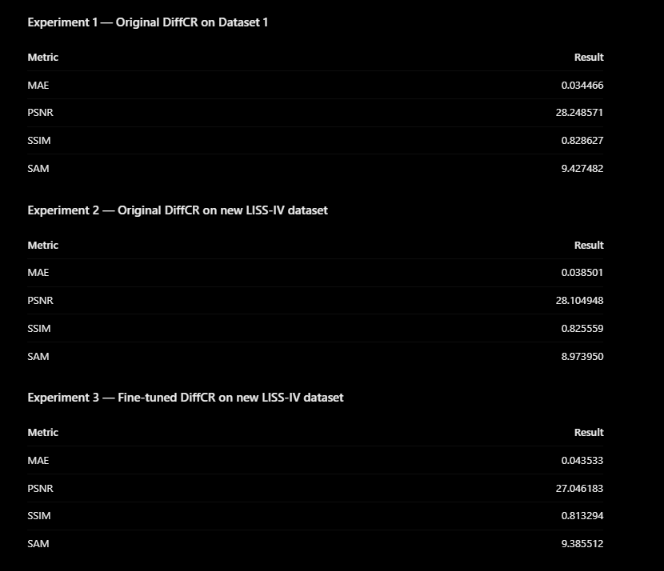

In [22]:
import random

random.seed()

selected_samples = []
attempts = 0
MAX_ATTEMPTS = 500
CLOUD_THRESHOLD = 0.12
MAX_CLOUD_PERCENTAGE = 50

while len(selected_samples) < 4 and attempts < MAX_ATTEMPTS:
    attempts += 1

    idx = random.randrange(len(test_dataset))
    cloudy_img, clear_img = test_dataset[idx]

    difference = torch.abs(cloudy_img - clear_img).mean(dim=0)

    cloud_percentage = (
        (difference > CLOUD_THRESHOLD).float().mean().item() * 100
    )

    if cloud_percentage < MAX_CLOUD_PERCENTAGE:
        selected_samples.append(
            (idx, cloudy_img, clear_img, cloud_percentage)
        )

        print(
            f"Accepted {len(selected_samples)}/4 | "
            f"Index: {idx} | "
            f"Estimated cloud coverage: {cloud_percentage:.2f}%"
        )

print("\nTotal attempts:", attempts)

if len(selected_samples) < 4:
    print("Could not find four suitable patches. Try adjusting CLOUD_THRESHOLD.")

Accepted 1/4 | Index: 22207 | Estimated cloud coverage: 47.16%
Accepted 2/4 | Index: 20102 | Estimated cloud coverage: 31.94%
Accepted 3/4 | Index: 19421 | Estimated cloud coverage: 22.93%
Accepted 4/4 | Index: 22063 | Estimated cloud coverage: 35.41%

Total attempts: 65


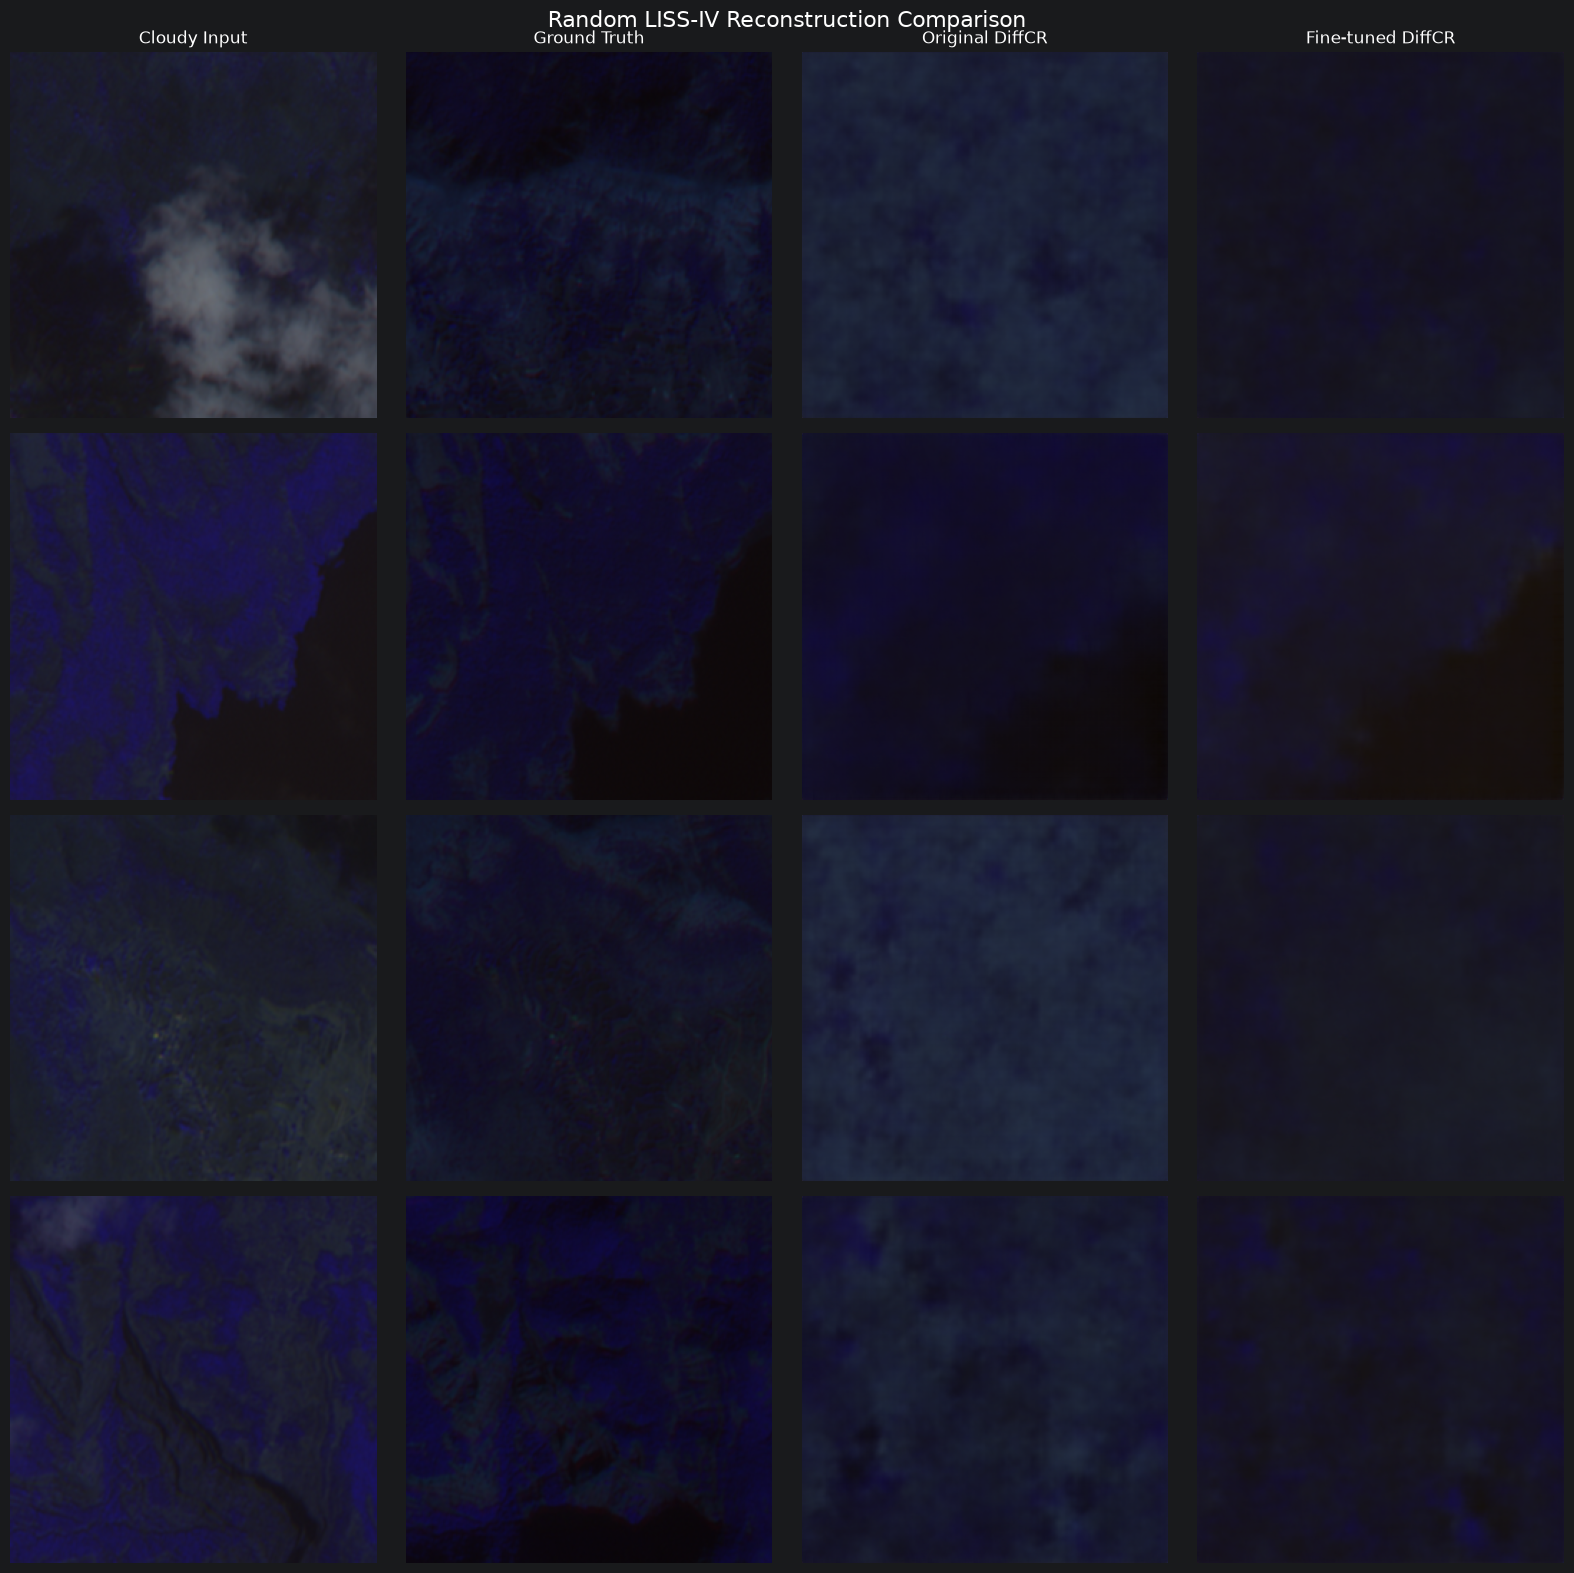

In [23]:
cloudy_vis = torch.stack(
    [sample[1] for sample in selected_samples]
).to(DEVICE)

clear_vis = torch.stack(
    [sample[2] for sample in selected_samples]
).to(DEVICE)

torch.manual_seed(42)
noise_vis = torch.randn_like(cloudy_vis)

with torch.no_grad():
    original_vis = sampler.sample(
        original_model,
        cloudy_vis,
        sampling_steps=SAMPLING_STEPS,
        initial_noise=noise_vis
    )

    finetuned_vis = sampler.sample(
        finetuned_model,
        cloudy_vis,
        sampling_steps=SAMPLING_STEPS,
        initial_noise=noise_vis
    )

images = [cloudy_vis, clear_vis, original_vis, finetuned_vis]

titles = [
    "Cloudy Input",
    "Ground Truth",
    "Original DiffCR",
    "Fine-tuned DiffCR"
]

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for row in range(4):
    for col in range(4):
        img = images[col][row].detach().cpu()
        img = ((img + 1) / 2).clamp(0, 1)
        img = img.permute(1, 2, 0).numpy()

        axes[row, col].imshow(img)
        axes[row, col].set_title(
            titles[col] if row == 0 else ""
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"Cloud: {selected_samples[row][3]:.1f}%",
        fontsize=11
    )

plt.suptitle("Random LISS-IV Reconstruction Comparison", fontsize=16)
plt.tight_layout()
plt.show()

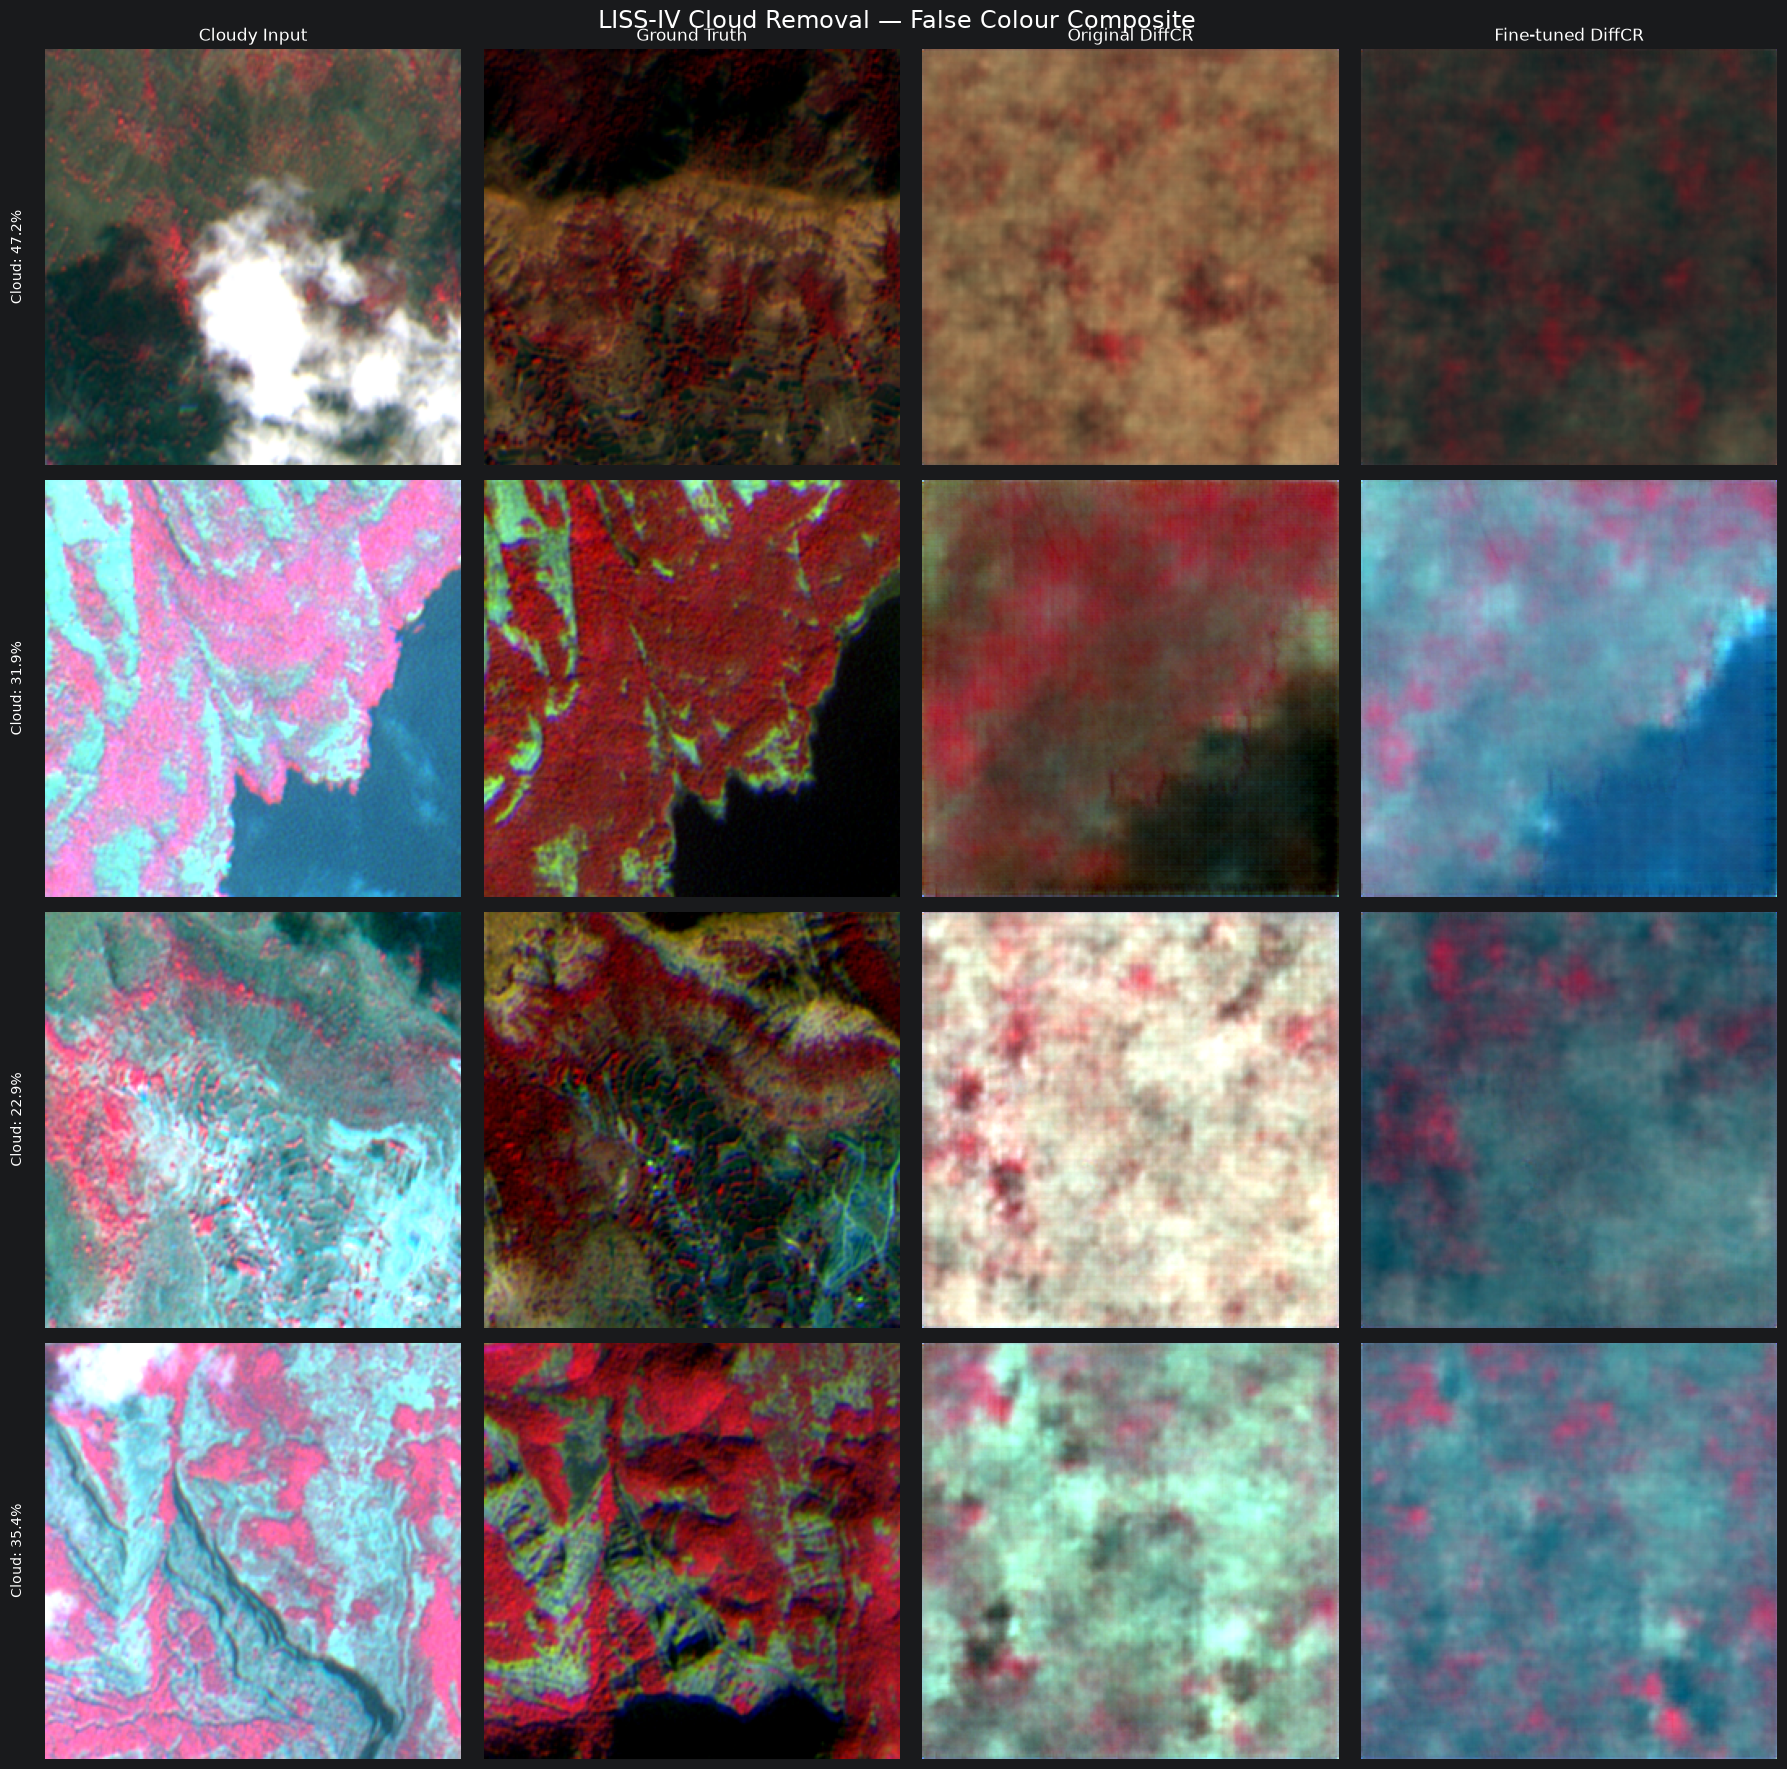

Saved: DiffCR_False_Color_Comparison.png


In [24]:
def to_false_color(tensor):
    img = ((tensor.detach().cpu().numpy() + 1) / 2)
    img = np.clip(img, 0, 1)

    # B2, B3, B4 -> B4, B3, B2 (FCC)
    img = img[[2, 1, 0], :, :]
    return np.transpose(img, (1, 2, 0))


fig, axes = plt.subplots(4, 4, figsize=(18, 18))

for row in range(4):

    sample_images = [
        cloudy_vis[row],
        clear_vis[row],
        original_vis[row],
        finetuned_vis[row]
    ]

    sample_images = [to_false_color(img) for img in sample_images]

    # Shared contrast limits across all four panels for this sample
    combined = np.concatenate(
        [img.reshape(-1, 3) for img in sample_images],
        axis=0
    )

    low = np.percentile(combined, 2, axis=0)
    high = np.percentile(combined, 98, axis=0)

    for col, img in enumerate(sample_images):
        img = (img - low) / (high - low + 1e-8)
        img = np.clip(img, 0, 1)

        axes[row, col].imshow(img)

        if row == 0:
            axes[row, col].set_title(
                [
                    "Cloudy Input",
                    "Ground Truth",
                    "Original DiffCR",
                    "Fine-tuned DiffCR"
                ][col],
                fontsize=12
            )

        axes[row, col].axis("off")

    axes[row, 0].text(
        -0.05, 0.5,
        f"Cloud: {selected_samples[row][3]:.1f}%",
        transform=axes[row, 0].transAxes,
        rotation=90,
        va="center",
        ha="right"
    )

plt.suptitle(
    "LISS-IV Cloud Removal — False Colour Composite",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "DiffCR_False_Color_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: DiffCR_False_Color_Comparison.png")

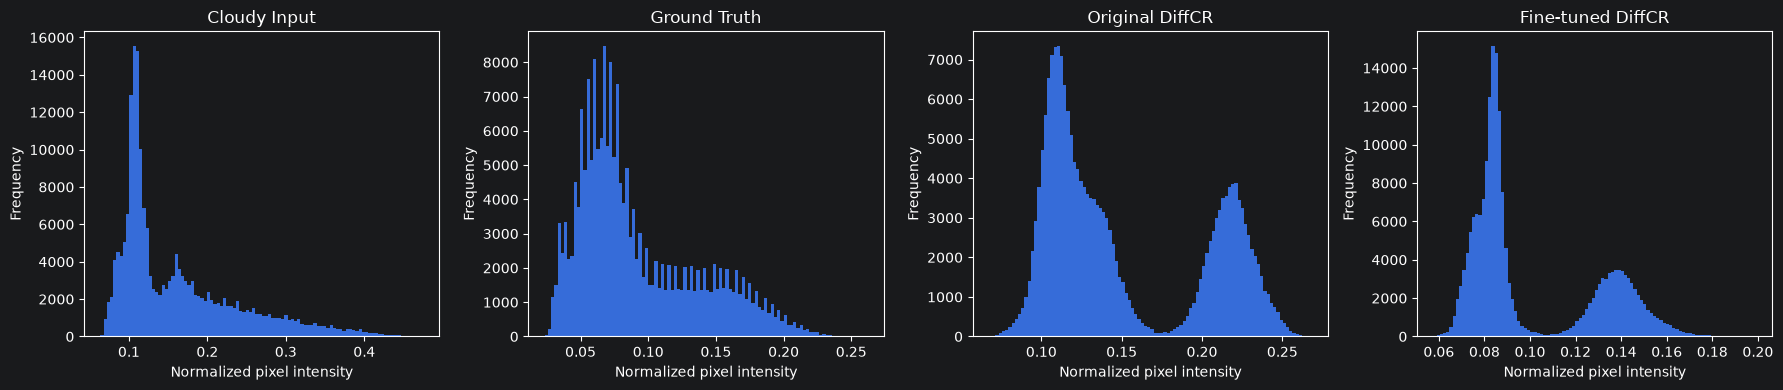

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

images = [
    cloudy_vis[0],
    clear_vis[0],
    original_vis[0],
    finetuned_vis[0]
]

titles = [
    "Cloudy Input",
    "Ground Truth",
    "Original DiffCR",
    "Fine-tuned DiffCR"
]

for ax, img, title in zip(axes, images, titles):
    img = ((img.detach().cpu() + 1) / 2).clamp(0, 1)
    values = img.numpy().ravel()

    ax.hist(values, bins=100)
    ax.set_title(title)
    ax.set_xlabel("Normalized pixel intensity")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()
